# Figure 5b–d · Figure S7 — Ant capacity control

This notebook runs two labelled checks: fresh Adult/matched-MLP smoke training and reanalysis of the archived 20-seed paper observations. The maze policies are separate. Full training is shown as a terminal command at the end and is never launched by Run All. See [protocol details](../docs/ant-flat.md).

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'ant-flat'
RUN_DIR = ROOT / "runs/notebooks/ant-flat-capacity-v2"
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: ant-flat | cuda:0 | runs/notebooks/ant-flat-capacity-v2


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 0.8 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 42.4 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 92.5 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 0.0 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 1.2 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 5.4 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,ant-flat,"connectome, mlp",[0]


Source/configuration SHA-256: `ec7a0a8e27306db0ced8bb688b0ef75d579aeb5120369af2ba3f31cac33f6374`

,stage,completed,elapsed seconds
0,prepare,True,0.80
1,train,True,42.40
2,evaluate,True,92.51
3,probe,True,0.00
4,analyze,True,1.23
5,plot,True,5.40


`analysis/seed_means.csv` (first eight rows)

...

`analysis/S7_seed_means.csv` (first eight rows)

,method,training_seed,friction,mean_x_velocity,functional_failure
0,connectome,0,0.50,0.006496,0.0
1,connectome,0,0.75,-0.001489,0.0
2,connectome,0,1.25,0.000554,0.0
3,connectome,0,1.50,-0.000111,0.0
4,mlp,0,0.50,0.004692,0.0
5,mlp,0,0.75,0.004325,0.0
6,mlp,0,1.25,0.001135,0.0
7,mlp,0,1.50,0.002975,0.0


`analysis/S7_summary.csv` (first eight rows)

,method,metric,friction,mean,ci95_low,ci95_high,n_seeds
0,connectome,mean_x_velocity,0.50,0.006496,NaN,NaN,1
1,connectome,mean_x_velocity,0.75,-0.001489,NaN,NaN,1
2,connectome,mean_x_velocity,1.25,0.000554,NaN,NaN,1
3,connectome,mean_x_velocity,1.50,-0.000111,NaN,NaN,1
4,connectome,functional_failure,0.50,0.000000,NaN,NaN,1
5,connectome,functional_failure,0.75,0.000000,NaN,NaN,1
6,connectome,functional_failure,1.25,0.000000,NaN,NaN,1
7,connectome,functional_failure,1.50,0.000000,NaN,NaN,1


`figures/paper/F5b_absolute_lateral.png`

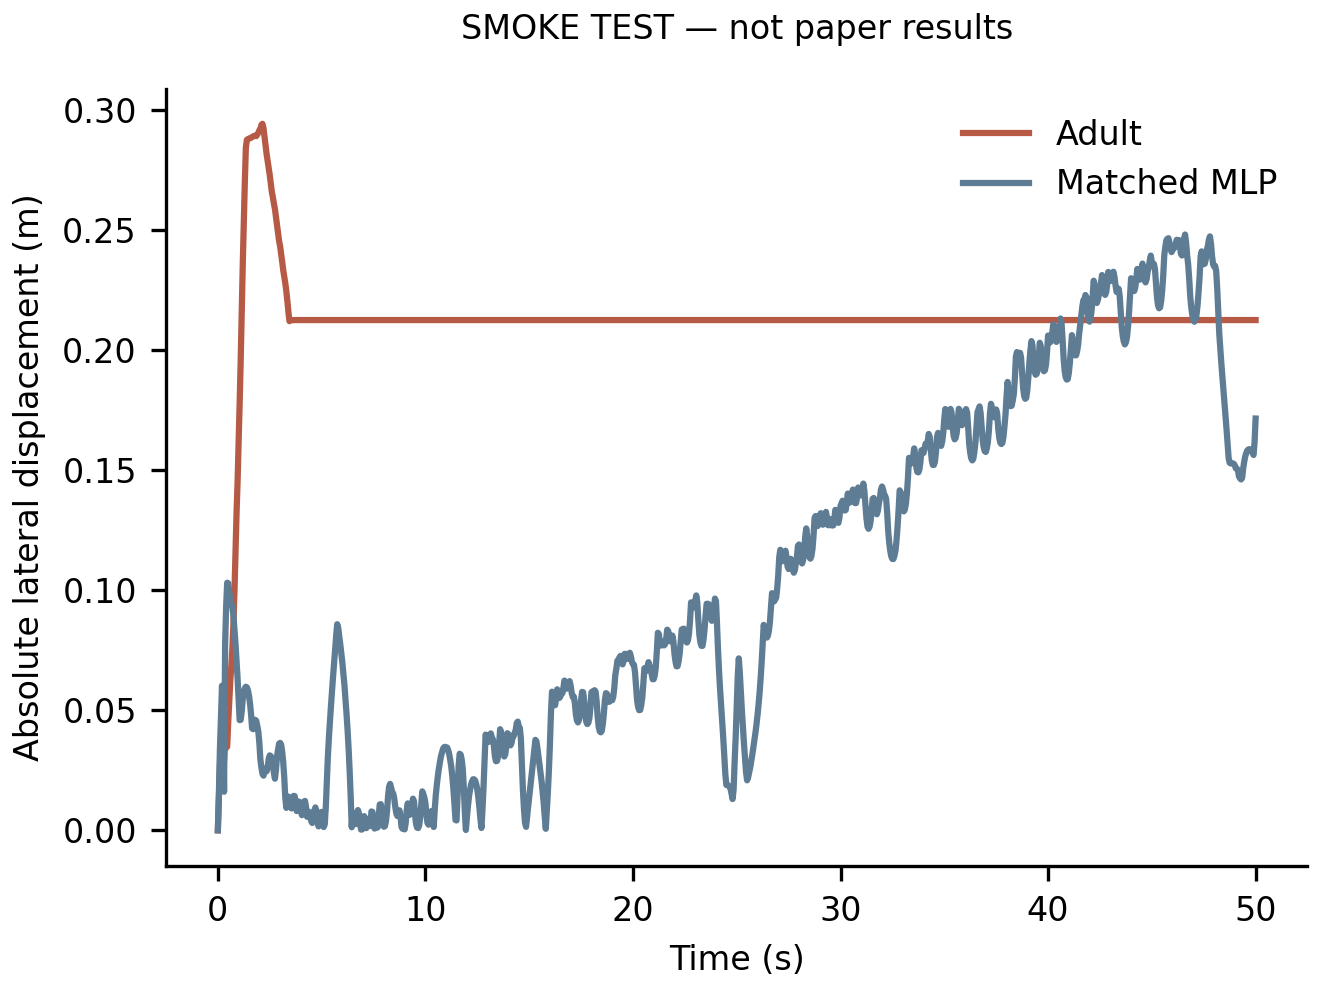

`figures/paper/F5b_forward.png`

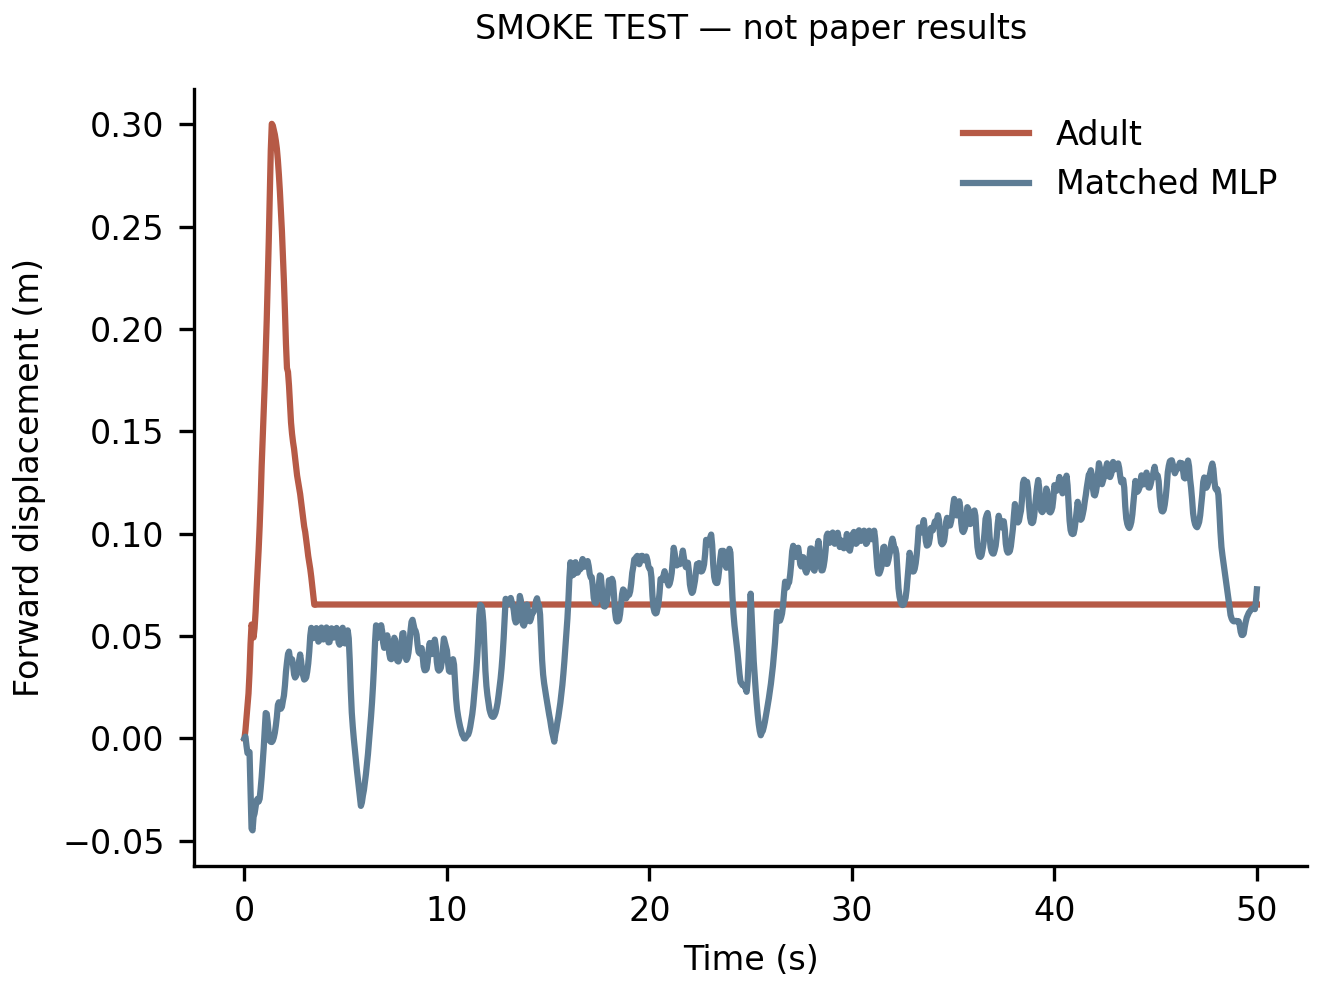

`figures/paper/F5c_path_efficiency.png`

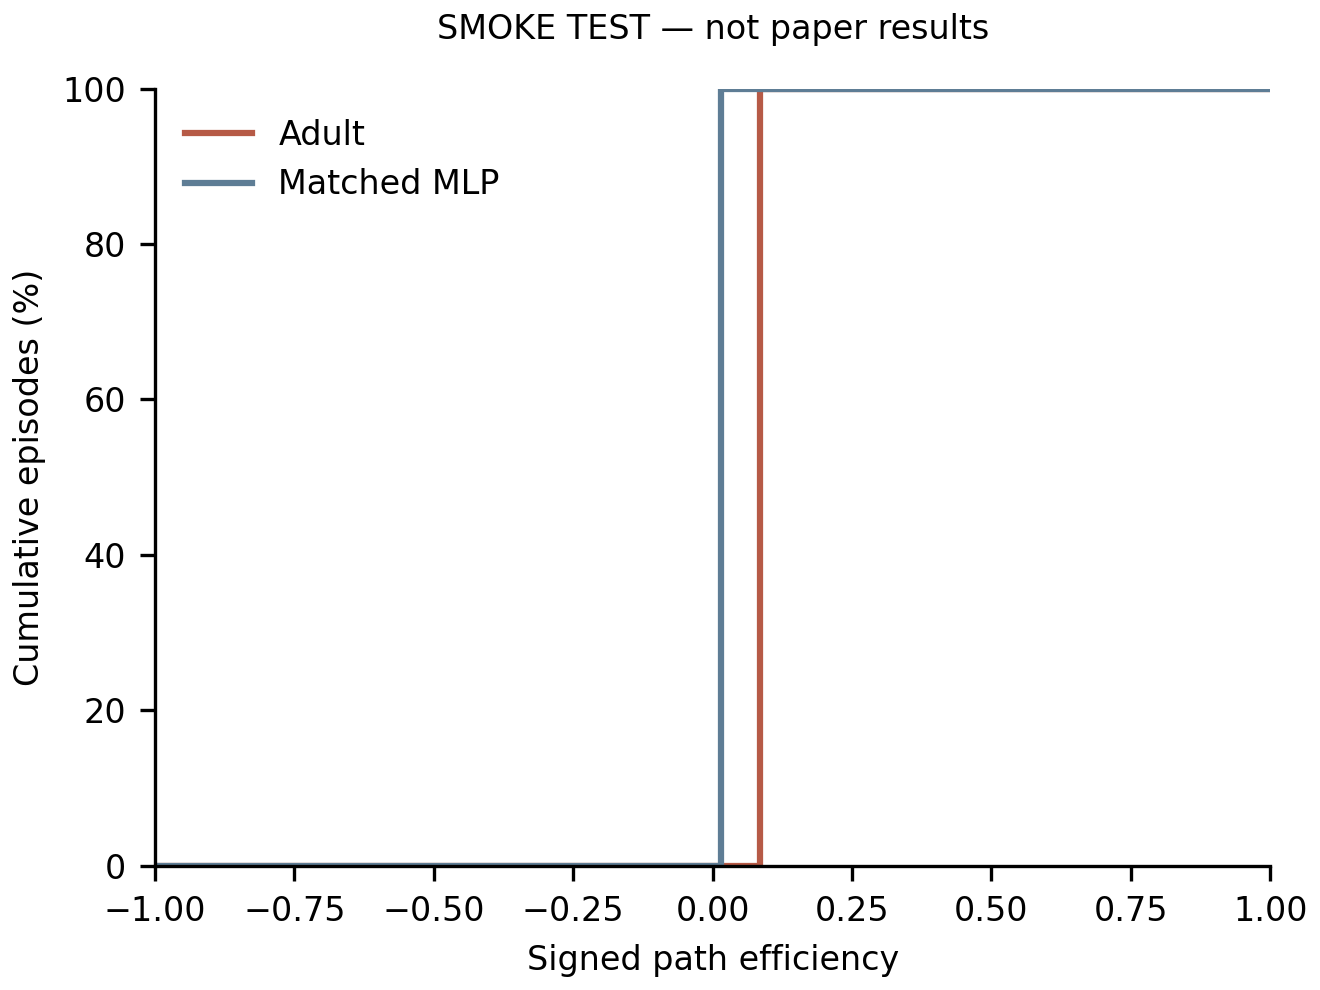

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Recompute the paper observations

**ARCHIVED PAPER DATA — no new training.** Recompute all 20 seed pairs, preserving the original 26 hypotheses and adding the three new endpoints (Holm 29). S7 is descriptive. The tables and plots below are separate from the smoke results above.

**ARCHIVED PAPER DATA: 20 paired training seeds; no training rerun.**

,contrast,metric,n_pairs,adult_mean,mlp_mean,difference,p_raw,p_holm_29,ci95_low,ci95_high
0,matched_flat_velocity,mean_x_velocity,20,1.936390,1.235719,0.700672,0.009851,0.059109,0.226411,1.133185
1,matched_flat_efficiency,path_efficiency,20,0.884566,0.793281,0.091285,0.006376,0.044634,0.033838,0.143805
2,matched_flat_failure,functional_failure,20,0.386000,0.298500,0.087500,0.054583,0.218330,0.005500,0.167500


,method,metric,friction,mean,ci95_low,ci95_high,n_seeds
0,connectome,mean_x_velocity,0.50,1.889161,1.630321,2.155543,20
1,connectome,mean_x_velocity,0.75,1.945859,1.678970,2.215181,20
2,connectome,mean_x_velocity,1.25,1.564546,1.341378,1.795719,20
3,connectome,mean_x_velocity,1.50,1.322834,1.169061,1.476371,20
4,connectome,functional_failure,0.50,0.396000,0.320000,0.470000,20
5,connectome,functional_failure,0.75,0.340000,0.268000,0.416000,20
6,connectome,functional_failure,1.25,0.648000,0.576000,0.714000,20
7,connectome,functional_failure,1.50,0.808000,0.726000,0.880000,20
8,mlp,mean_x_velocity,0.50,1.216472,0.941003,1.529310,20
9,mlp,mean_x_velocity,0.75,1.229850,0.948192,1.547970,20


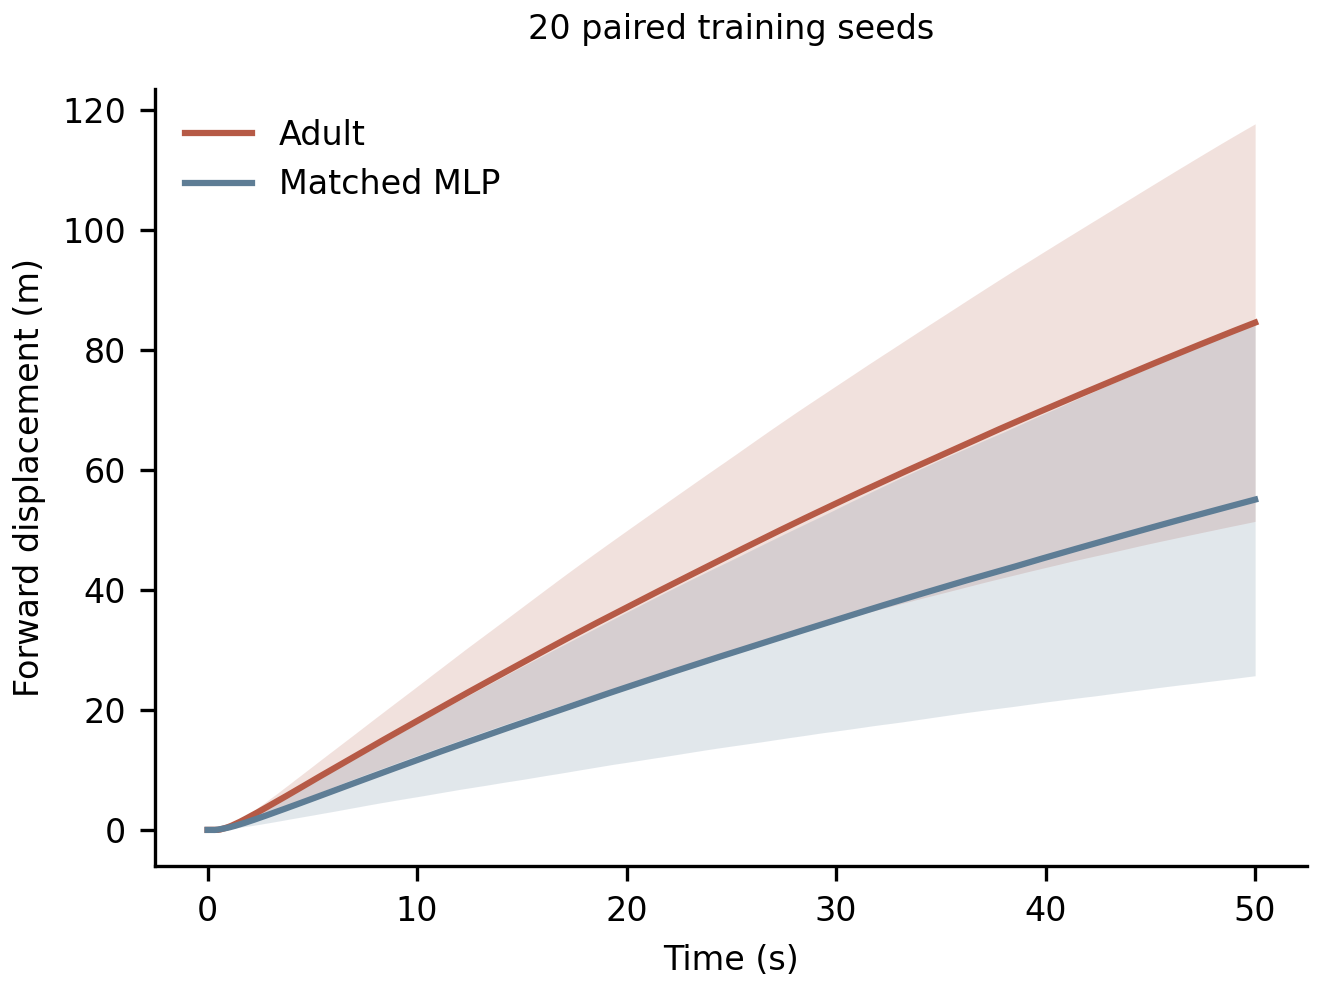

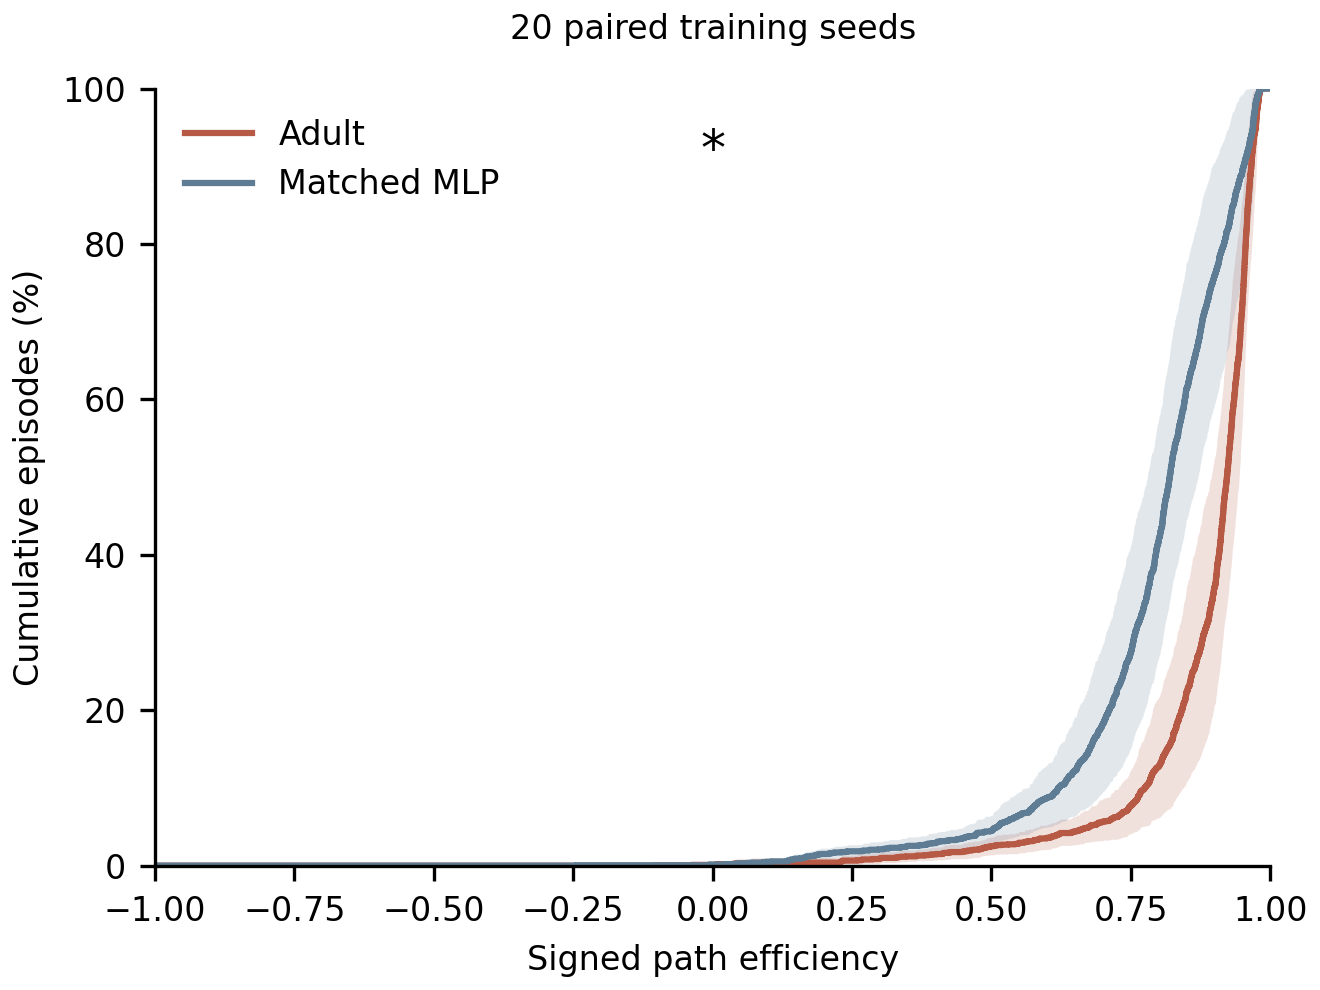

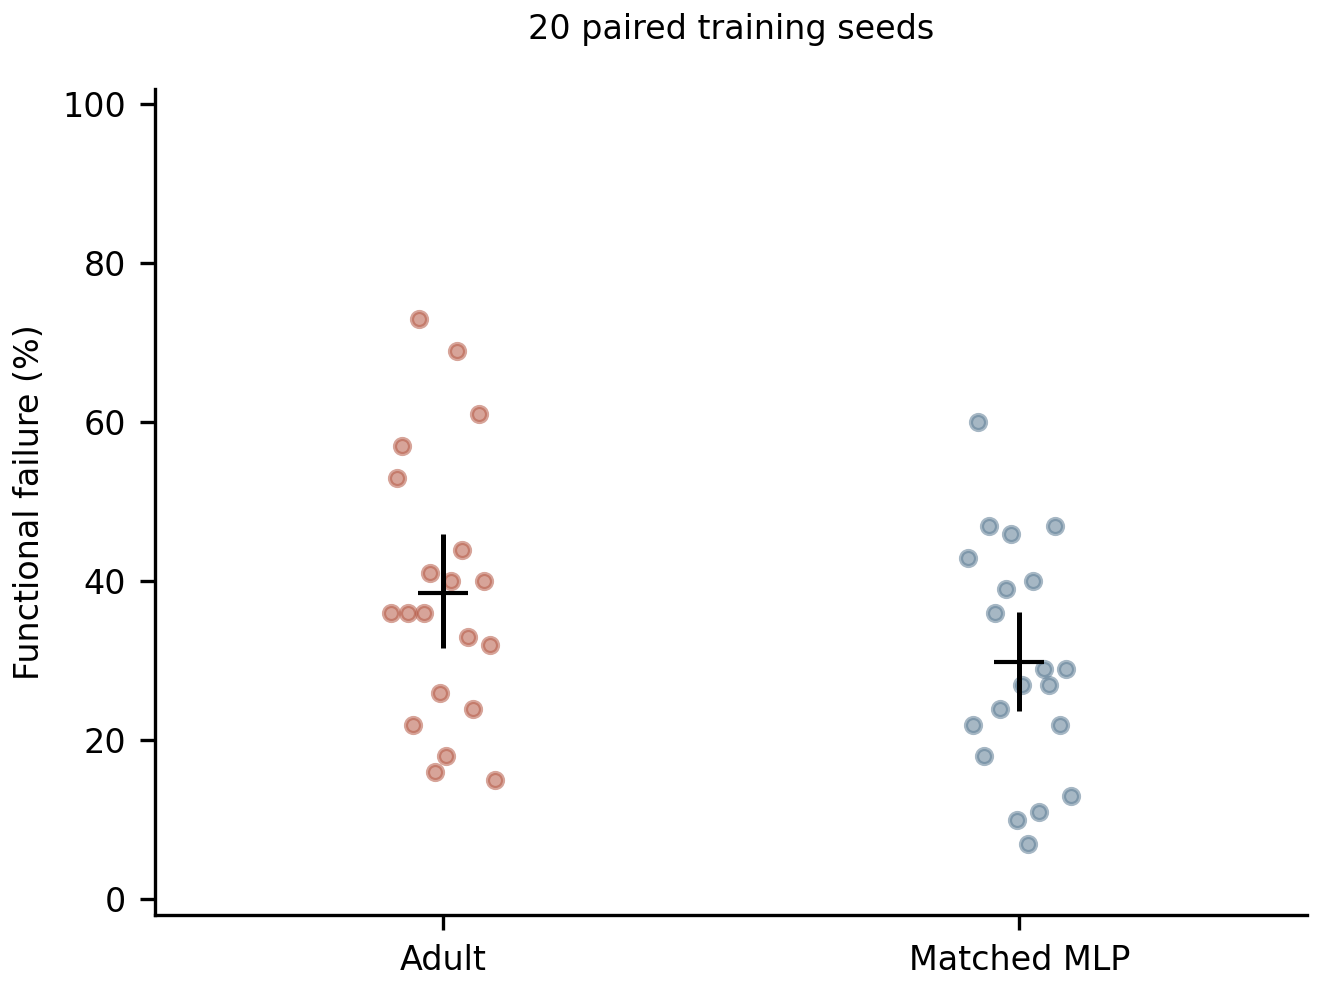

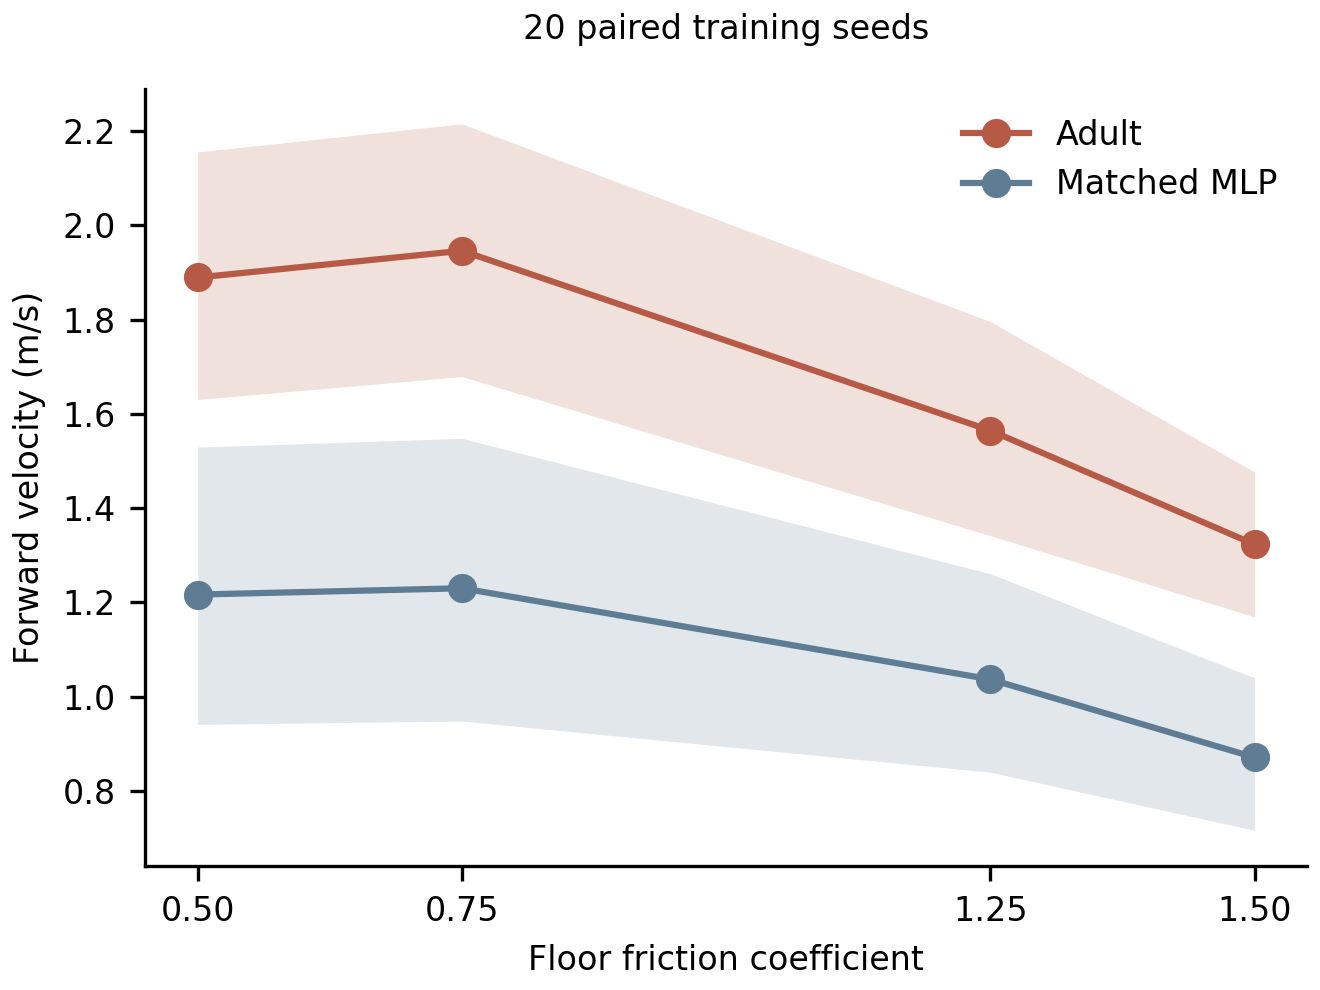

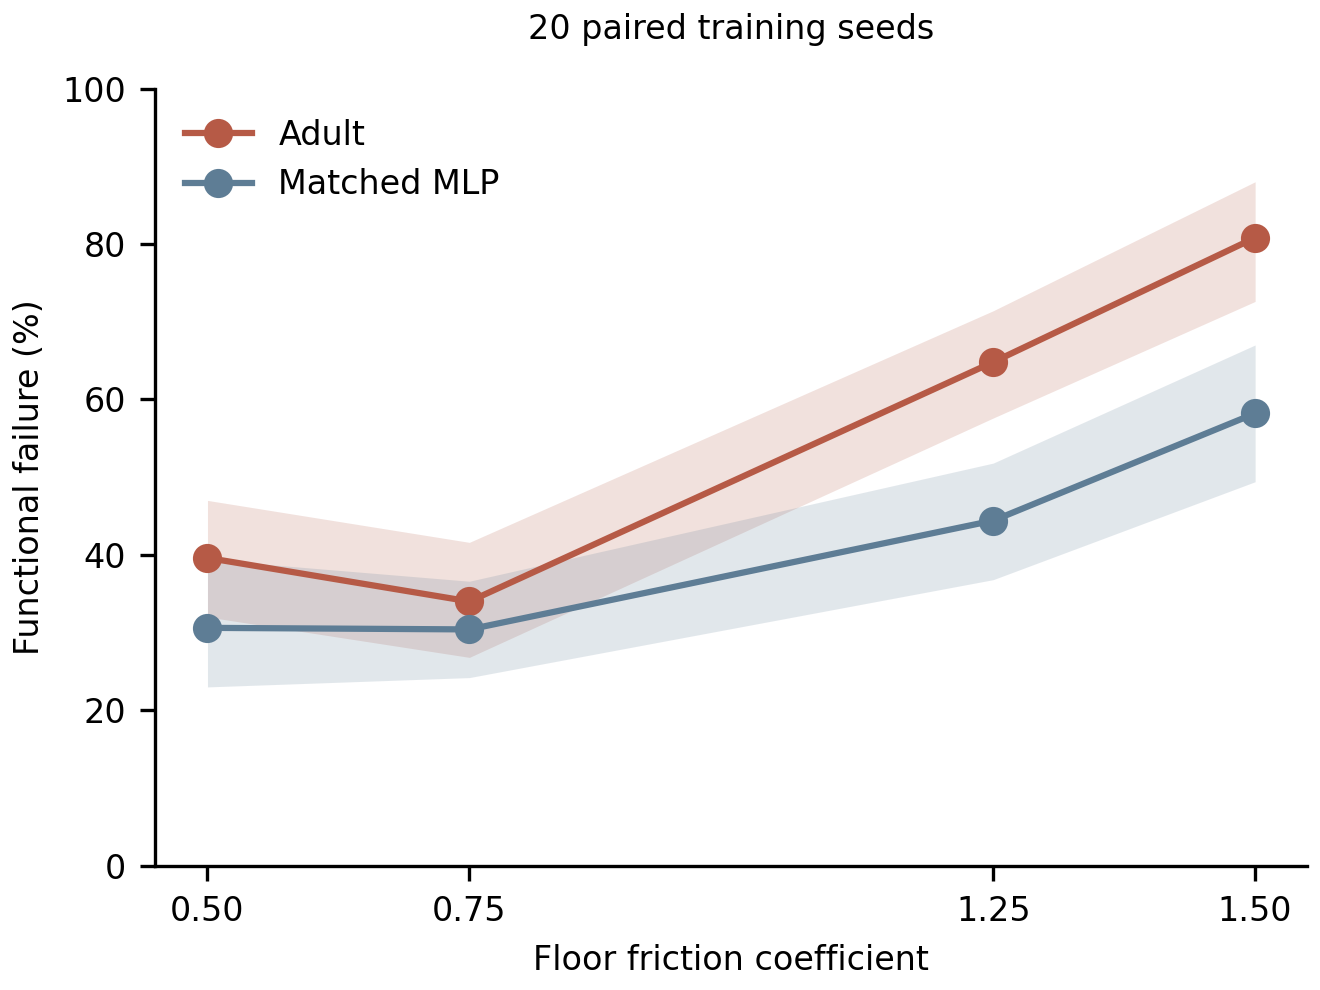

In [9]:
import subprocess
import pandas as pd
from IPython.display import display, Image, Markdown

REFERENCE_DIR = ROOT / "runs/notebooks/ant-flat-reference"
reference_env = dict(os.environ, OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
subprocess.run([sys.executable, "-m", "flycontrol", "ant-reference", "--output", str(REFERENCE_DIR)],
               cwd=ROOT, env=reference_env, check=True, capture_output=True, text=True)
display(Markdown("**ARCHIVED PAPER DATA: 20 paired training seeds; no training rerun.**"))
display(pd.read_csv(REFERENCE_DIR / "analysis/paired_comparisons.csv"))
display(pd.read_csv(REFERENCE_DIR / "analysis/S7_summary.csv"))
for panel in ["F5b_forward", "F5c_path_efficiency", "F5d_failure", "S7_mean_x_velocity", "S7_functional_failure"]:
    display(Image(filename=str(REFERENCE_DIR / f"figures/paper/{panel}.png")))

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/05_ant_flat.py --run-dir runs/ant-flat --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config ant-flat --run-dir runs/ant-flat --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
